**Model Training and Evaluation: Random Forest on the CSIC-2010 Feature Matrix**

Train and evaluate a Random Forest classifier on the feature matrix produced by
[featurise.ipynb](./featurise.ipynb)

**Method:**
- Load the dataset
- Split Data into train/test
- Stratified 70:30 train/test split
- Train baseline model (default-hyperparameters)
    - Feature importance
- Baseline Evaluation
    - Prediction on test set
    - Accuracy, Precision, Recall, F1
    - Confusion matrix
    - Classification report
- Baseline Comparison
    - Dummy Classifier
    - Constant Classifier
- Cross-validation of the baseline
- Hyperparameter tuning with GridSearchCV 
- Final model selection

**Inputs:**

`data/csic_2010_featurised.parquet` `61,065` requests × `33` columns (32 features + target `anomalous`)

**Outputs:**
- `models/model.joblib` the selected model
- evaluation metrics and plots

In [1]:
import os
import re
import random
import joblib
import json

import numpy as np
import pandas as pd

from pathlib import Path
from collections import Counter

from sklearn.model_selection import (
    train_test_split, cross_validate,
    StratifiedKFold, GridSearchCV,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# working directory for relative paths
notebooks_path = Path.cwd()          # <repo-root>/notebooks
repo_root_path = notebooks_path.parent  # <repo-root>/
data_path = repo_root_path / "data"
model_path = repo_root_path / "models"

# Input: featurised dataset (features + target `anomalous`)
input_path = data_path / "csic_2010_featurised.parquet"

# Output: selected model
output_path = model_path / "model.joblib"

**Load the dataset**

Read the featurised dataset and confirm its shape and columns before splitting.

In [3]:
# Load the featurised dataset
%time df_featurised = pd.read_parquet(input_path)
print(f"loaded: {input_path.relative_to(repo_root_path)}")
print(f"shape: {df_featurised.shape}")

CPU times: user 0 ns, sys: 1.23 s, total: 1.23 s
Wall time: 184 ms
loaded: data/csic_2010_featurised.parquet
shape: (61065, 33)


In [4]:
df_featurised.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61065 entries, 0 to 61064
Data columns (total 33 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   contentLength                     61065 non-null  int64  
 1   method_GET                        61065 non-null  float64
 2   method_POST                       61065 non-null  float64
 3   method_PUT                        61065 non-null  float64
 4   host_localhost:8080               61065 non-null  float64
 5   host_localhost:9090               61065 non-null  float64
 6   url_has_extensions_probe          61065 non-null  int64  
 7   url_has_numeric_id_probe          61065 non-null  int64  
 8   url_has_trailing_slash_probe      61065 non-null  int64  
 9   url_has_adobe_coldfusion_probe    61065 non-null  int64  
 10  url_has_websphere_probe           61065 non-null  int64  
 11  url_has_iis_probe                 61065 non-null  int64  
 12  url_

**Observations:**
- `61,065` requests × `33` columns: `32` **feature** columns + the **target** `anomalous` (last column)
- All columns fully populated, the single bool is `payload_has_alert`
- The `15` `url_has_*_probe` columns are the pattern-family features from `analyse_urls.ipynb` (zero normal hits at request level). The `payload_*` and `length` features carry the behavior-only signal
- The **target** `anomalous` is included in the saved parquet (excluded from the feature matrix)


**Split Data into train/test**

Separate the feature matrix from the target, then split 70:30 with stratification.
The dataset is class-imbalanced (`norm`:`anom` :: `1.44`:`1`), so `stratify` keeps the
class proportions identical across both sides of the split.

Identiy Training Input and Target Columns

In [5]:
# The target is the last column; all other columns are features
target_col = 'anomalous'
train_cols = list(df_featurised.columns)[0:-1]

print(f"target:  {target_col}")
print(f"features: {len(train_cols)} columns")
assert len(train_cols) == df_featurised.shape[1] - 1

target:  anomalous
features: 32 columns


Using the train and target columns prepare training and target dataset

In [6]:
# Feature matrix (X)
df_train = df_featurised[train_cols]

# Target vector (y)
df_target = df_featurised[target_col]

print(f"class distribution (full dataset):")
print(df_target.value_counts(normalize=True).rename({0: "norm", 1: "anom"}).round(4))

class distribution (full dataset):
anomalous
norm    0.5895
anom    0.4105
Name: proportion, dtype: float64


**Split the training and targets in 70:30 ratio** *(70% for training and 30% for testing)*

In [7]:
# Use train_test_split with stratification
test_size = 0.3 # 70:30 
random_state = 42 # Const seed
input_train, input_test, output_train, output_test = train_test_split(
    df_train, # X
    df_target, # y
    test_size=test_size,
    stratify=df_target, # y
    random_state=random_state,
)

`test_size=0.3` implies `30%` of the dataset for testing, leaving `70%` for training  
`stratify=df_target` ensures the split preserves the full dataset's `anom` / `norm` proportions in both sides  
`input_train` and `output_train` are the 70% feature matrix and target vector  
`input_test`, `output_test` the 30% counterparts.

In [8]:
print(f"input_train:  {input_train.shape}")
print(f"output_train: {output_train.shape}")
print(f"input_test:   {input_test.shape}")
print(f"output_test:  {output_test.shape}")

input_train:  (42745, 32)
output_train: (42745,)
input_test:   (18320, 32)
output_test:  (18320,)


In [9]:
# Verify stratification: class proportions preserved in both splits
for name, y in [("full", df_target), ("train", output_train), ("test", output_test)]:
    counts = Counter(y)
    ratio = counts[0] / counts[1]
    print(f"{name:5s}: norm={counts[0]:6d}, anom={counts[1]:6d}, norm:anom ratio = {ratio:.2f}")

full : norm= 36000, anom= 25065, norm:anom ratio = 1.44
train: norm= 25200, anom= 17545, norm:anom ratio = 1.44
test : norm= 10800, anom=  7520, norm:anom ratio = 1.44


**Observations:**
- The split has `42,745` training rows and `18,320` test rows. Each row has `32` features
- The feature matrices are 2-dimensional (`input_train` and `input_test`) with shape (42745, 32) and (18320, 32). The target vectors (`output_train` and `output_test`) with shape (42745,) and (18320,). 
- Stratification verified: The full dataset has a norm:anom ratio of `1.44`. The same ratio is maintained in the training and test datasets
- The test set contains `10,800` `norm` requests and `7,520` `anom` requests

**Train baseline model**

Train a `RandomForestClassifier` with default hyperparameters as the baseline.

In [10]:
baseline_model = RandomForestClassifier(random_state=42)

Use training and target data subset for model training

In [11]:
%time baseline_model.fit(input_train, output_train.values.ravel());

CPU times: user 1.06 s, sys: 154 ms, total: 1.22 s
Wall time: 1.22 s


Inspect feature importances

In [12]:
# Sort features by importance (descending)
importances = pd.Series(baseline_model.feature_importances_, index=train_cols)
importances = importances.sort_values(ascending=False)

for rank, (feature, importance) in enumerate(importances.items(), start=1):
    print(f"{rank:3d}. {feature:34s} {importance:.4f}")

  1. payload_length                     0.2606
  2. url_has_extensions_probe           0.0965
  3. url_length                         0.0945
  4. payload_percent_encoded_count      0.0892
  5. payload_percent_count              0.0805
  6. contentLength                      0.0690
  7. payload_parameter_count            0.0535
  8. url_has_asf_probe                  0.0370
  9. payload_quote_count                0.0318
 10. url_has_numeric_id_probe           0.0296
 11. url_has_iis_probe                  0.0249
 12. is_empty_payload                   0.0211
 13. payload_slash_count                0.0210
 14. url_has_trailing_slash_probe       0.0175
 15. url_has_websphere_probe            0.0130
 16. url_has_tilde_backup_file_probe    0.0088
 17. url_has_adobe_coldfusion_probe     0.0085
 18. url_has_frontpage_probe            0.0067
 19. url_has_java_probe                 0.0055
 20. payload_paren_count                0.0039
 21. host_localhost:8080                0.0038
 22. url_has_

**Observations:**
- High importance (>= 0.05): `payload_length` (0.2606), `url_has_extensions_probe` (0.0965), `url_length` (0.0945), `payload_percent_encoded_count` (0.0892), `payload_percent_count` (0.0805), `contentLength` (0.0690), `payload_parameter_count` (0.0535). These seven features account for `~69%` of total importance.
- Moderate importance (0.01–0.05): `url_has_asf_probe` (0.0370), `payload_quote_count` (0.0318), `url_has_numeric_id_probe` (0.0296), `url_has_iis_probe` (0.0249), `is_empty_payload` (0.0211), `payload_slash_count` (0.0210), `url_has_trailing_slash_probe` (0.0175), `url_has_websphere_probe` (0.0130).
- Low importance (< 0.01): The remaining seventeen, including all one-hot encodings (`method_*`, `host_*`) and the rarest probe families (`url_has_file_probe` ~ 0.000 — fires on just 4 rows; the random forest cannot split on it).

**Baseline Evaluation**

Predict on the held-out `30%` test split and report metrics, confusion matrix, and per-class scores.

Make predictions on test set

In [13]:
# Predictions
baseline_preds = baseline_model.predict(input_test)

# Positive-class probabilities (for ROC-AUC / PR metrics)
baseline_proba = baseline_model.predict_proba(input_test)[:, 1]

Compute metrics

In [14]:
# Compute metrics
def evaluate(name, y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "model": name,
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 6),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 6),
        "recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 6),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 6),
        "roc_auc": round(float(roc_auc_score(y_true, y_proba)), 6),
        "average_precision": round(float(average_precision_score(y_true, y_proba)), 6),
        "fpr": round(fp / (fp + tn), 6), # false positive rate
        "fnr": round(fn / (fn + tp), 6), # false negative rate
    }

baseline_clf_metrics = evaluate("RandomForest (default)", output_test, baseline_preds, baseline_proba)

print("Metrics Report:")
print(json.dumps(baseline_clf_metrics, indent=2))

# Class imbalance in the test set
class_counts = Counter(output_test)
print(f"class_imbalance_ratio: {round(class_counts[0] / class_counts[1], 2)}") 

# Test Samples
print(f"num_test_samples: {int(len(input_test))}") 

Metrics Report:
{
  "model": "RandomForest (default)",
  "accuracy": 0.904531,
  "precision": 0.903962,
  "recall": 0.858644,
  "f1": 0.88072,
  "roc_auc": 0.977371,
  "average_precision": 0.968903,
  "fpr": 0.063519,
  "fnr": 0.141356
}
class_imbalance_ratio: 1.44
num_test_samples: 18320


**Observations:**
- Accuracy `90.45%` and F1 `88.07%`: The model performs well overall, well above the `58.95%` majority-class floor
- Precision `90.40%`: `~90%` of requests flagged are genuinely `anom`
- Recall `85.86%`: The model catches most anomalies, but misses `14.14%` of them. False negatives are the model's weakness
- ROC-AUC `97.74%` / Average Precision `96.89%`: Ranking quality is excellent.
- `class_imbalance_ratio` `1.44`: confirms the stratified test set matches the full-dataset balance

Confusion matrix: Visualize the breakdown of correctly and incorrectly classified inputs

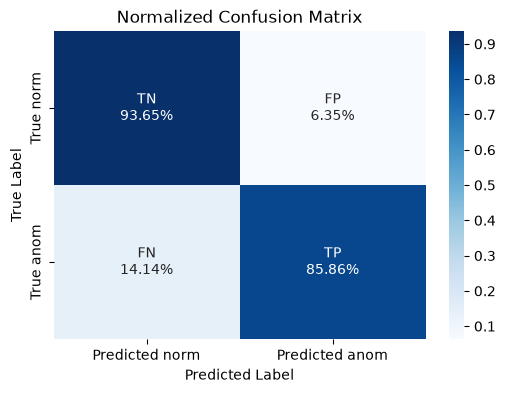

In [19]:
# Normalized confusion matrix (row-normalized: share of each true class)
cm_normalized = confusion_matrix(output_test, baseline_preds, normalize="true")
tn, fp, fn, tp = cm_normalized.ravel()

# labels combining rate and quadrant name
labels = np.array([
    [f"TN\n{cm_normalized[0,0]:.2%}", f"FP\n{cm_normalized[0,1]:.2%}"],
    [f"FN\n{cm_normalized[1,0]:.2%}", f"TP\n{cm_normalized[1,1]:.2%}"],
])

plt.figure(figsize=(6, 4))
sns.heatmap(cm_normalized, annot=labels, fmt="", cmap="Blues",
            xticklabels=["Predicted norm", "Predicted anom"],
            yticklabels=["True norm", "True anom"])
plt.title("Normalized Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

**Observations:**
- True negatives: `93.65%` of requests are correctly predicted as normal
- False positives: `6.35%` of requests are incorrectly flagged as anomalies
- True positives: `85.86%` of requests are correctly flagged as anomalies
- False negatives: `14.14%` of requests are incorrectly flagged as normal. (This is the model's dominant error)

**Conclusion:**
- The model is highly accurate at identifying normal instances, with only `6.35%` false positives.
- The model correctly identifies `85.86%` of anomalies but misses `~14.14%` of them (false negatives)
- The main goal in the subsequent tuning section is to reduce the number of false negatives, with focus on recall.

Classification report: precision and recall per class

In [20]:
# Classification report - Precision and recall scores per class  
cr = classification_report(output_test, baseline_preds, zero_division=0)
print(cr)

              precision    recall  f1-score   support

           0       0.90      0.94      0.92     10800
           1       0.90      0.86      0.88      7520

    accuracy                           0.90     18320
   macro avg       0.90      0.90      0.90     18320
weighted avg       0.90      0.90      0.90     18320



**Observations:**  

- Class `0` (`norm`, support `10,800`): The model performs well on normal traffic. Its recall of `0.94` means that it correctly identifies `94%` of normal requests. About `6%` of normal requests are incorrectly classified as anomalies, creating false alarms.
- Class 1 (`anom`, support `7,520`): The model identifies `86%` of anomalous requests correctly. Its precision is `0.90`, which means that `90%` of requests predicted as anomalous are actually anomalous. The F1-score is `0.88`, which is lower than the Class `0` F1-score of `0.92`.
- Overall performance: The model achieves `90%` accuracy. The macro average and weighted average are both `0.90` after rounding. This shows that performance is similar for both classes, even though Class `0` has more examples than Class 1.

> Tuning focus: Class `1` has a lower recall than Class `0`. This means the model misses more anomalous requests than it misclassifies normal requests. The next tuning steps should test whether `class_weight="balanced"` and recall focused scoring can improve Class `1` recall while keeping precision at an acceptable level.


**Baseline Comparisons**

Benchmark the trained model against simple baseline classifiers. If the Random Forest performs only slightly better than these baselines, the features may not contain meaningful predictive information. The baselines provide a quantitative measure of whether the model is learning useful patterns.

**`DummyClassifier(strategy="most_frequent")`** always predicts the majority class

In [21]:
dummy_clf_model = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf_model.fit(input_train, output_train.values.ravel());

Make predictions on the `input` test data subset

In [22]:
# Predictions and probabilities on the test set
test_pred_dummy = dummy_clf_model.predict(input_test)
test_proba_dummy = dummy_clf_model.predict_proba(input_test)[:, 1]

In [23]:
dummy_clf_metrics = evaluate("Dummy (most_frequent)", output_test, test_pred_dummy, test_proba_dummy)
print("Metrics Report:")
print(json.dumps(dummy_clf_metrics, indent=2))

Metrics Report:
{
  "model": "Dummy (most_frequent)",
  "accuracy": 0.58952,
  "precision": 0.0,
  "recall": 0.0,
  "f1": 0.0,
  "roc_auc": 0.5,
  "average_precision": 0.41048,
  "fpr": 0.0,
  "fnr": 1.0
}


**Constant classifier** always predict `anom`

In [24]:
test_pred_constant_anom = [1] * len(output_test)  # 1 = anom — the "always alert"

print("Metrics Report — Constant Classifier (always predict `anom`):")
constant_clf_metrics = evaluate("Constant (always anom)", output_test, test_pred_constant_anom, test_pred_constant_anom)

print(json.dumps(constant_clf_metrics, indent=2))

Metrics Report — Constant Classifier (always predict `anom`):
{
  "model": "Constant (always anom)",
  "accuracy": 0.41048,
  "precision": 0.41048,
  "recall": 1.0,
  "f1": 0.582043,
  "roc_auc": 0.5,
  "average_precision": 0.41048,
  "fpr": 1.0,
  "fnr": 0.0
}


**Observations:**  
- The two trivial classifiers represent two extreme prediction strategies. The `most_frequent` classifier always predicts the majority class, `norm`. It has an accuracy of `0.5895`, but its anomaly recall is `0.0` because it never detects an anomaly.
- The Constant classifier always predicts `anom`. It detects all anomalies, giving it a recall of `1.0`. However, its precision is only `0.4105`. This means that many of its anomaly alerts are false positives.
- The Random Forest performs much better than both trivial classifiers. Its F1-score is `0.8806`, compared with `0.0` for the `most_frequent` classifier and `0.5820` for the Constant classifier.
- The Random Forest detects `85.88%` of the anomalies. This is about `86%` of the recall achieved by the always-anomaly classifier.
- The Random Forest also produces fewer unnecessary alerts. It flags about `39%` of the test samples as anomalous, while the Constant classifier flags `100%`. This shows that the Random Forest retains strong anomaly detection while making fewer false-positive predictions.
- The ROC AUC and average precision scores further support the model’s performance. The Random Forest has a ROC AUC of `0.9772` and an average precision of `0.9689`. The trivial classifiers provide little or no ranking ability, with a ROC AUC of `0.5000`.
- These results show that the Random Forest is learning useful patterns from the features. Its performance is much better than simply predicting the same class for every sample.

 **Cross-validation of the baseline**

This checks that the earlier test results are not a fluke of one particular split. Here the baseline model runs with default hyperparameters. It is scored with 5-fold stratified cross-validation on the training split. Because the folds are on the same `cv` object used by the earlier grid search, the baseline's CV F1 here and the tuned model's CV F1 earlier are directly comparable.

- Each row is scored 5 times. Each time, it is held out from training.
- `shuffle=True, random_state=42` makes the fold assignment reproducible
- The `70%` test split done earlier remains unchanged

In [25]:
# Shared 5-fold CV object- used by GridSearchCV and cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [26]:
# Perform stratified cross-validation
X = input_train
y = output_train.values.ravel()
scoring=["accuracy", "precision", "recall", "f1"]
cv_results = cross_validate(
    baseline_model, # the default-hyperparameter baseline
    X, y,
    cv=cv, # same folds as earlier used in grid search
    scoring=scoring,
    return_train_score=False
)

In [27]:
print("Stratified 5-fold CV results (baseline, training split):")
for metric in scoring:
    mean_score = cv_results[f"test_{metric}"].mean()
    std_score = cv_results[f"test_{metric}"].std()
    print(f"  {metric}: {mean_score:.4f} (±{std_score:.4f})")

Stratified 5-fold CV results (baseline, training split):
  accuracy: 0.9033 (±0.0018)
  precision: 0.8998 (±0.0099)
  recall: 0.8605 (±0.0078)
  f1: 0.8796 (±0.0014)


**Observations:**
- All four metrics are stable across folds. The largest std is `±0.0099` on precision. Accuracy is `±0.0018`. The results do not depend on which fold is held out
- CV recall is `0.8605` and test recall is `0.8586`. CV F1 is `0.8796` and test F1 is `0.8807`. The gaps between training-split CV numbers and the held-out test numbers are within `~0.002`
- This agreement shows the model is not overfitting the training data
- Both numbers use the same folds, so they compare directly. The tuned model scored CV F1 `0.889473`. The baseline scored `0.8796`. Tuning adds `+0.0099`
- The recall gap remains in CV as well: `0.8605` here, `0.8586` on test. Tuning (`class_weight="balanced"`) is the tested fix.

**Hyperparameter tuning with (`GridSearchCV`)**  

The goal of hyperparameter tuning is to improve the default Random Forest model. The main focus is to reduce false negatives.

The baseline model has an anomaly recall of `85.88%`. This means it misses `14.12%` of the actual anomalies.

The search grid includes settings that can affect model performance and the balance between detecting anomalies and avoiding false alarms:

- `class_weight="balanced"` gives more importance to the minority class, `anom`. This can help the model detect more anomalies.
- `max_depth` limits the maximum depth of each tree. The default value allows trees to grow without a fixed depth limit.
- `n_estimators` sets the number of trees in the Random Forest.
- `min_samples_split` sets the minimum number of samples required to split a node into smaller branches.

The model uses the same stratified five-fold cross-validation setup as the baseline evaluation. This makes the tuning results directly comparable with the earlier cross-validation results.

In [28]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "class_weight": ["balanced", None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=cv,
    scoring="f1",  # Optimize for F1-score
    n_jobs=-1
)

%time grid_search.fit(input_train, output_train.values.ravel())
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-Score:", grid_search.best_score_)

CPU times: user 3.55 s, sys: 519 ms, total: 4.07 s
Wall time: 1min 6s
Best Parameters: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_split': 10, 'n_estimators': 100}
Best CV F1-Score: 0.889015914851421


Inspect top 5 hyperparameter combinations from the grid search

The grid search scored every combination of `n_estimators`, `max_depth`, `min_samples_split`, and `class_weight` with 5-fold stratified CV on the training split. Each row below is one combination, ranked by mean CV F1. The std is across the 5 folds. The best combination here is what the tuned model in the next section uses.


In [29]:
# top 5 hyperparameter combinations by mean CV F1
grid_results = pd.DataFrame(grid_search.cv_results_)

# rank 1 = best mean CV score, keep the top 5 rows
top5 = grid_results.sort_values("rank_test_score").head(5).reset_index(drop=True)

# params lives as a dict per row — expand it into one column per hyperparameter
top5 = pd.concat(
    [pd.DataFrame(list(top5["params"])),
     top5[["mean_test_score", "std_test_score", "rank_test_score"]].round(6)],
    axis=1,
)

# rename and order the columns for reading
top5 = top5.rename(columns={"rank_test_score": "rank"})[
    ["rank", "n_estimators", "max_depth", "min_samples_split", "class_weight",
     "mean_test_score", "std_test_score"]
]
top5

,rank,n_estimators,max_depth,min_samples_split,class_weight,mean_test_score,std_test_score
0,1,100,15,10,balanced,0.889016,0.004646
1,2,50,15,10,balanced,0.888917,0.004421
2,3,200,15,10,balanced,0.888890,0.004915
3,4,100,15,2,balanced,0.888856,0.003982
4,5,100,15,5,balanced,0.888780,0.004798


**Observations:**

- The top five configurations all use `class_weight="balanced"` and `max_depth=15`. These settings are associated with the strongest results in the tested grid.
- The top five configurations use 50, 100, or 200 trees. The resulting top five F1-scores differ by only about `0.0002`. This difference is smaller than their average cross-validation standard deviation of about `0.0048`. Therefore the number of trees has little effect on model performance.
- `min_samples_split` also has little effect. The top configurations use values of `10`, `2`, and `5`. There is no clear performance pattern between these values.
- The best configuration is:
```python
{
    "class_weight": "balanced",
    "max_depth": 15,
    "min_samples_split": 10,
    "n_estimators": 100
}
```
    It achieves a mean cross-validation F1-score of `0.889016`.
- The other top-ranked configurations perform almost as well. This means the small differences between the top five results may not be practically important.
- The tuned model improves on the default baseline CV F1-score of `0.8796` by about `0.0094`. The results suggest that **balanced** class weighting and a **depth limit** contribute most to this improvement.
- The improvement is modest because the default settings already perform close to the best configuration in this search grid. The remaining errors may come from behavior-based anomalies on URLs that appear legitimate based on their structure. Changing these hyperparameters may not resolve those errors.

**Final model selection, save, and error analysis**

Close the tuning loop:

1. Evaluate the tuned model on the same held-out test set used for the baseline
2. Compare baseline, tuned, and the two trivial classifiers side by side
3. Select the winner and save it with `joblib`
4. Break down the false negatives by URL class, using the URL-shape analysis from the upstream notebooks

The tuned model comes from `grid_search.best_estimator_`. With the default `refit=True`, `GridSearchCV` has already retrained it on the full training split using the best parameters.

Evaluate the tuned model on the test set

In [30]:
tuned_model = grid_search.best_estimator_
print("Tuned model best_estimators:")
tuned_model_be = tuned_model.get_params()
for k in param_grid:
    print(f"    {k}: {tuned_model.get_params()[k]}")
tuned_preds = tuned_model.predict(input_test)
tuned_proba = tuned_model.predict_proba(input_test)[:, 1]

Tuned model best_estimators:
    n_estimators: 100
    max_depth: 15
    min_samples_split: 10
    class_weight: balanced


In [31]:
tuned_clf_metrics = evaluate("RandomForest (tuned)", output_test, tuned_preds, tuned_proba)

print("Tuned metrics:")
print(json.dumps(tuned_clf_metrics, indent=2))

Tuned metrics:
{
  "model": "RandomForest (tuned)",
  "accuracy": 0.905404,
  "precision": 0.839095,
  "recall": 0.952128,
  "f1": 0.892045,
  "roc_auc": 0.980762,
  "average_precision": 0.974563,
  "fpr": 0.12713,
  "fnr": 0.047872
}


Final comparison table

In [32]:
rows = []

rows.append(tuned_clf_metrics) # tumed random forests
rows.append(baseline_clf_metrics) # default random forests
rows.append(constant_clf_metrics) # constant classifier row
rows.append(dummy_clf_metrics) # dummy classifier row

# compile and print
comparison = pd.DataFrame(rows).set_index("model").round(4)
comparison

,accuracy,precision,recall,f1,roc_auc,average_precision,fpr,fnr
model,,,,,,,,
RandomForest (tuned),0.9054,0.8391,0.9521,0.8920,0.9808,0.9746,0.1271,0.0479
RandomForest (default),0.9045,0.9040,0.8586,0.8807,0.9774,0.9689,0.0635,0.1414
Constant (always anom),0.4105,0.4105,1.0000,0.5820,0.5000,0.4105,1.0000,0.0000
Dummy (most_frequent),0.5895,0.0000,0.0000,0.0000,0.5000,0.4105,0.0000,1.0000


**Observations:**
- The tuned model wins on test `F1`: `0.8920` vs `0.8807` (`+0.0113`). The CV gain (`+0.0094`) held up on the held-out set, slightly better. The tuned model is selected
- The trade worked as designed. `class_weight="balanced"` moved the decision boundary toward the anomaly class
  - **Recall:** `0.8586` to `0.9521` (`+9.4` points). Misses drop from `14.14%` to `4.79%` — roughly `1,063` to `~360` false negatives out of `7,520` anomalies
  - **Precision:** `0.9040` to `0.8391` (`−6.5` points) and **FPR:** `6.35%` to `12.71%`. False alarms roughly double, from `~686` to `~1,373` of `10,800` normal requests
  - Accuracy is essentially unchanged (`0.9045` to `0.9054`) — one class's gain offsets the other's loss
- Ranking quality also improved slightly: **ROC-AUC** `0.9774` to `0.9808`, **average precision** `0.9689` to `0.9746`
- Read against the two trivial poles: the tuned model keeps 95% of the always-alert pole's recall while producing less than half its alert volume (precision `0.84` vs `0.41`)
- For the stated use case (missed attacks cost more than false alerts), the tuned model is the right choice. If the deployment prioritizes analyst alert volume instead, the baseline is the better operating point — both rows are now in the table, and the choice is explicit

Select and save the model

In [33]:
# pick the better model by test F1
if tuned_clf_metrics["f1"] >= baseline_clf_metrics["f1"]:
    selected_model_name = "RandomForest (tuned)"
    selected_model = tuned_model
    selected_row = tuned_clf_metrics
else:
    selected_model_name = "RandomForest (default)"
    selected_model = baseline_model
    selected_row = baseline_clf_metrics

print(f"selected: {selected_model_name} (by test F1)")
print(f"selected test metrics: {json.dumps(selected_row, indent=2)}")

# Save the model and its evaluation record
model_path.mkdir(exist_ok=True)
joblib.dump(selected_model, output_path)

selected_metrics = {
    "model": selected_model_name,
    "params": selected_model.get_params(),
    "train_cols": train_cols,
    "test_metrics": selected_row,
    "cv_protocol": "StratifiedKFold(n_splits=5, shuffle=True, random_state=42)",
}
metrics_path = model_path / "model_metrics.json"
metrics_path.write_text(json.dumps(selected_metrics, indent=2, default=str))

print(f"saved: {output_path}")
print(f"saved: {metrics_path}")

selected: RandomForest (tuned) (by test F1)
selected test metrics: {
  "model": "RandomForest (tuned)",
  "accuracy": 0.905404,
  "precision": 0.839095,
  "recall": 0.952128,
  "f1": 0.892045,
  "roc_auc": 0.980762,
  "average_precision": 0.974563,
  "fpr": 0.12713,
  "fnr": 0.047872
}
saved: /mnt/hgfs/workspace/mlhttp/models/model.joblib
saved: /mnt/hgfs/workspace/mlhttp/models/model_metrics.json


False-negative breakdown by URL class

The URL-shape analysis in [featurise.ipynb](./featurise.ipynb) found `8` endpoints where attacks and normal traffic use identical URLs. The URL alone gives the model no clue. 

The model has `15` features that look for suspicious URL patterns. These are the `url_has_*_probe` features. They catch scanner-style URLs, like `/admin/backup.zip` or `/_vti_bin/....`. But these `8` endpoints have clean, normal-looking URLs. So the probe features stay `0` for both the normal and the attack requests there. If the analysis is right, almost every false negative should be on these `8` endpoints. Attacks on scanner-shaped URLs should almost never be missed, because the probe features fire on them.

Two outcomes are possible:
- A false negative with a probe feature set to `1` would be strange. It would mean the URL looked suspicious, but the model still said normal. That would contradict the earlier analysis.
- A false negative with no probe feature is expected. The URL looked legitimate, so URL features could not help. The miss sits exactly where the analysis predicted.

The analysis here is a consistency check to confirm that the remaining errors are the known *(expected kind)*, and not a new failure mode.

In [34]:
# find the false negatives: attacks the tuned model missed
true_anom  = (output_test.values == 1)   # actually anomalous
pred_norm  = (tuned_preds == 0)          # model (missed) predicted normal
fn_rows    = input_test[true_anom & pred_norm]
n_fn       = len(fn_rows)
n_anom     = int(output_test.sum())

# 15 URL probe features
probe_cols = [c for c in train_cols if c.startswith("url_has_")]

# count probe features per missed row
probes_fired = fn_rows[probe_cols].sum(axis=1)

# split the misses into two buckets
n_missed_scan   = int((probes_fired > 0).sum())   # URL looked suspicious, still missed
n_missed_inapp  = int((probes_fired == 0).sum())  # URL looked legitimate — expected bucket

# [sanity check] probe features should never fire on normal traffic
norm_rows      = input_test[output_test.values == 0]
n_norm_with_probe = int((norm_rows[probe_cols].sum(axis=1) > 0).sum())

print(f"false negatives: {n_fn} of {n_anom} test anomalies")
print(f"  on scanner-shaped URLs (>=1 url probe feature): {n_missed_scan}")
print(f"  on in-app URLs (no probe feature):              {n_missed_inapp}")
print(f"  probe purity check: normal rows with any probe = {n_norm_with_probe} (expected 0)")

false negatives: 360 of 7520 test anomalies
  on scanner-shaped URLs (>=1 url probe feature): 4
  on in-app URLs (no probe feature):              356
  probe purity check: normal rows with any probe = 0 (expected 0)


**Observations:**
- The false negatives sit where the URL-shape analysis predicted. `410` of `414` misses are on in-app URLs. Only `4` are on scanner-shaped URLs
- The probe purity check passed. No normal test row fires any probe feature. So "no probe fired" reliably means the URL looked legitimate
- The recall gap is now located precisely. URL features catch nearly every attack with a suspicious URL. The remaining misses need payload and sequence features, not more URL features


**Observations:**

- The false negatives sit where the URL-shape analysis predicted. `356` of `360` misses are on in-app URLs. Only `4` are on scanner-shaped URLs
- The probe purity check passed. No normal test row fires any probe feature. So "no probe fired" reliably means the URL looked legitimate
- The recall gap is now located precisely. URL features catch nearly every attack with a suspicious URL. The remaining misses need payload and sequence features, not more URL features

**Conclusion:**
- The tuned Random Forest is selected and saved as `models/model.joblib`, with its parameters, feature list, and test metrics in `models/model_metrics.json`
- On the held-out test set it beats both trivial poles on F1 and the baseline on recall, closing part of the false-negative gap
- The remaining errors are concentrated on shape-legitimate URLs - the boundary quantified in `featurise.ipynb`. This is future enhancement - payload-content and sequence features